# Jin et al. single-cell UMAP visualisations

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path
# Set this directory to the location of the cleaned Jin count data.
DATA_DIR = Path("/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data")
INPUT_FILE = DATA_DIR / "adata_cleaned_int32.h5ad"

adata = sc.read_h5ad(INPUT_FILE)

In [2]:
adata.obsm["X_umap"] = np.asarray(adata.obsm["X_umap"])

print(type(adata.obsm["X_umap"]))
print(adata.obsm["X_umap"].shape)

<class 'numpy.ndarray'>
(1161340, 2)


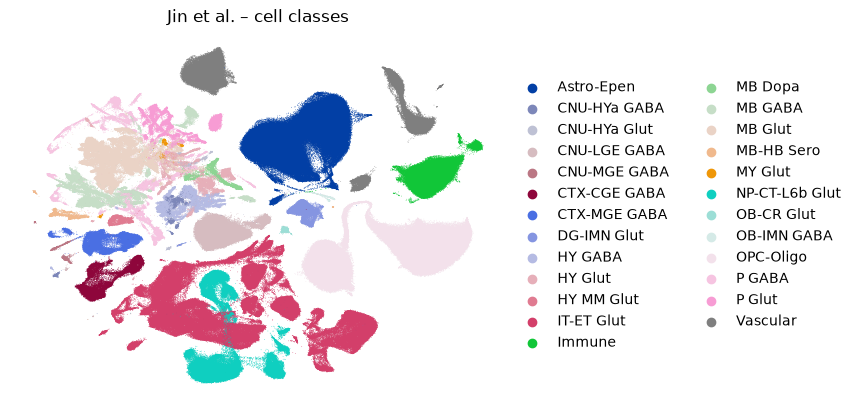

In [3]:
sc.pl.umap(
    adata,
    color="class_label",
    size=1,
    legend_loc="right margin",
    frameon=False,
    title="Jin et al. – cell classes",
)

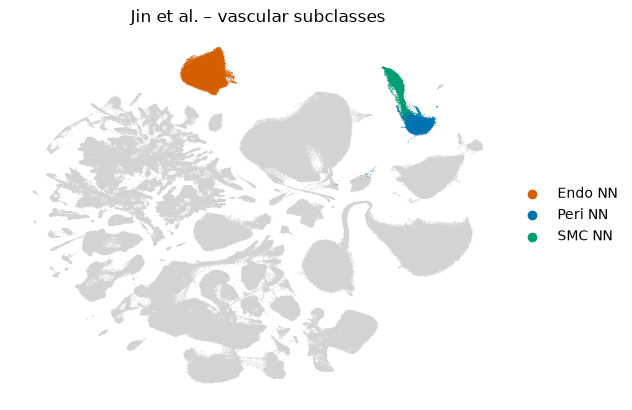

In [4]:
# Subclasses to highlight
subclasses = ["Endo NN", "Peri NN", "SMC NN"]

# Create a column containing only the selected subclasses
adata.obs["vascular_subclass"] = (
    adata.obs["subclass_label"]
    .astype("object")
    .where(adata.obs["subclass_label"].isin(subclasses), None)
)

# Convert to categorical with only the three selected categories
adata.obs["vascular_subclass"] = pd.Categorical(
    adata.obs["vascular_subclass"],
    categories=subclasses
)

# Define colours
adata.uns["vascular_subclass_colors"] = [
    "#D55E00",  # Endo NN
    "#0072B2",  # Peri NN
    "#009E73",  # SMC NN
]

# Plot
sc.pl.umap(
    adata,
    color="vascular_subclass",
    size=1,
    legend_loc="right margin",
    na_color="lightgrey",
    na_in_legend=False,
    frameon=False,
    title="Jin et al. – vascular subclasses",
)

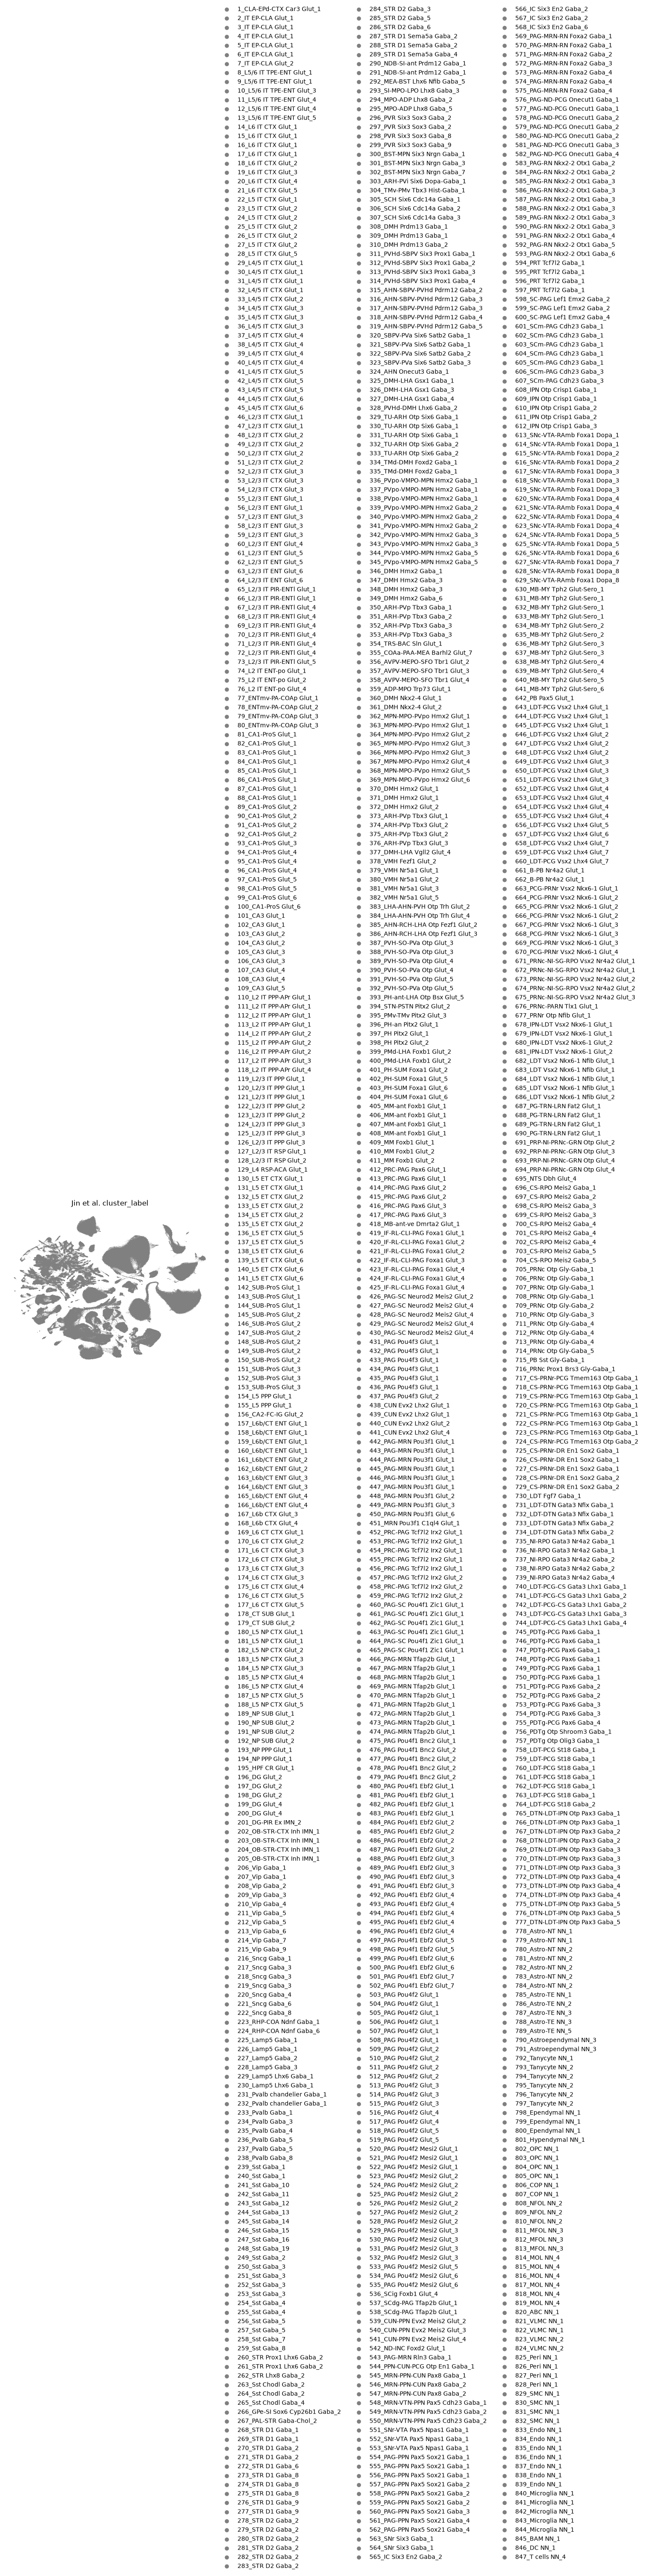

In [5]:
sc.pl.umap(
    adata,
    color="cluster_label",
    size=1,
    legend_loc="right margin",
    frameon=False,
    title="Jin et al. cluster_label",
)

In [ ]:
# Define a distinct colour for each cluster
cluster_colors = {
    "825_Peri NN_1": "#084594",
    "826_Peri NN_1": "#2171B5",
    "827_Peri NN_1": "#6BAED6",
    "828_Peri NN_1": "#BDD7E7",

    "829_SMC NN_1": "#006D2C",
    "830_SMC NN_1": "#31A354",
    "831_SMC NN_1": "#74C476",
    "832_SMC NN_1": "#BAE4B3",

    "833_Endo NN_1": "#A50F15",
    "834_Endo NN_1": "#DE2D26",
    "835_Endo NN_1": "#FB6A4A",
    "836_Endo NN_1": "#FC9272",
    "837_Endo NN_1": "#FCAE91",
    "838_Endo NN_1": "#FDD0A2",
    "839_Endo NN_1": "#FEEDDE",
}

# Ensure only the selected clusters are retained
adata_vascular = adata[
    adata.obs["cluster_label"].isin(cluster_colors)
].copy()

# Set categorical order
adata_vascular.obs["cluster_label"] = (
    adata_vascular.obs["cluster_label"]
    .astype("object")
    .astype("category")
)

# Assign colours according to category order
adata_vascular.uns["cluster_label_colors"] = [
    cluster_colors[c]
    for c in adata_vascular.obs["cluster_label"].cat.categories
]

# Plot UMAP
sc.pl.umap(
    adata_vascular,
    color="cluster_label",
    size=2,
    legend_loc="right margin",
    frameon=False,
    title="Jin et al. – vascular clusters",
)